ögrencının günluk calısma saati
günlük uyku sati
derse katılım oranı
sosyal medya kullanım süresi
-------------------
ORTALAMA KAÇ ALIR ?
LİNEAR REGRESSİON 
75 puan
82 puan
93 puan
------------------
bir evin metrekare ve oda sayısına göre fiyatını tahmin
bir aracın km ve yasına göre 2.el piyasa göre 
bir işletmenin reklam harcaması 700$ -> Getiri kaç dolar ?
bir ürünün geçmiş satış verilerine göre talebini tahmin etmek için
-----------------
REGRESYON : SAYISAL DEGER TAHMİNİ
SINIFLANDIRMA: BİR KATEGORİ VEYA SINIF TAHMİNİ
------------------


In [41]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler,MinMaxScaler
from sklearn.linear_model import LinearRegression

from sklearn.metrics import(
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [42]:
df = pd.read_csv("linear_regression_ogrenci_notlari_synthetic.csv")

In [43]:
df.head()

,calisma_saati,uyku_suresi,ders_katilim_orani,sosyal_medya_saati,sinav_puani
0,5.1,8.7,77.1,2.2,65.0
1,2.4,8.2,67.1,2.1,48.4
2,6.0,6.4,71.8,5.6,64.4
3,6.4,5.5,87.5,3.8,70.6
4,0.6,4.0,78.0,2.8,30.8


In [44]:
df.shape

(500, 5)

In [45]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 5 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   calisma_saati       500 non-null    float64
 1   uyku_suresi         500 non-null    float64
 2   ders_katilim_orani  500 non-null    float64
 3   sosyal_medya_saati  500 non-null    float64
 4   sinav_puani         500 non-null    float64
dtypes: float64(5)
memory usage: 19.7 KB


In [47]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
calisma_saati,500.0,4.4772,1.910461,0.2,3.200,4.50,5.700,10.0
uyku_suresi,500.0,7.1504,1.111959,4.0,6.400,7.20,7.825,10.0
ders_katilim_orani,500.0,77.4684,14.432519,33.7,68.075,78.00,87.825,100.0
sosyal_medya_saati,500.0,2.9662,1.704749,0.2,1.800,2.95,4.100,8.4
sinav_puani,500.0,61.8426,12.403915,22.8,53.375,62.30,70.200,99.7


In [48]:
df.isnull().sum()

calisma_saati         0
uyku_suresi           0
ders_katilim_orani    0
sosyal_medya_saati    0
sinav_puani           0
dtype: int64

In [49]:
df.duplicated().sum()

np.int64(0)

In [50]:
numeric_df =  df.select_dtypes(include="number")

In [52]:
Q1 = numeric_df.quantile(0.25)

Q3 = numeric_df.quantile(0.75)

IQR =  Q3 - Q1

In [53]:
lower_bound = Q1 - 1.5 * IQR

upper_bound = Q3 + 1.5 * IQR

In [54]:
outlier_count = (
    (numeric_df < lower_bound) |
    (numeric_df > upper_bound)
).sum()

In [55]:
outlier_count

calisma_saati         4
uyku_suresi           5
ders_katilim_orani    4
sosyal_medya_saati    2
sinav_puani           2
dtype: int64

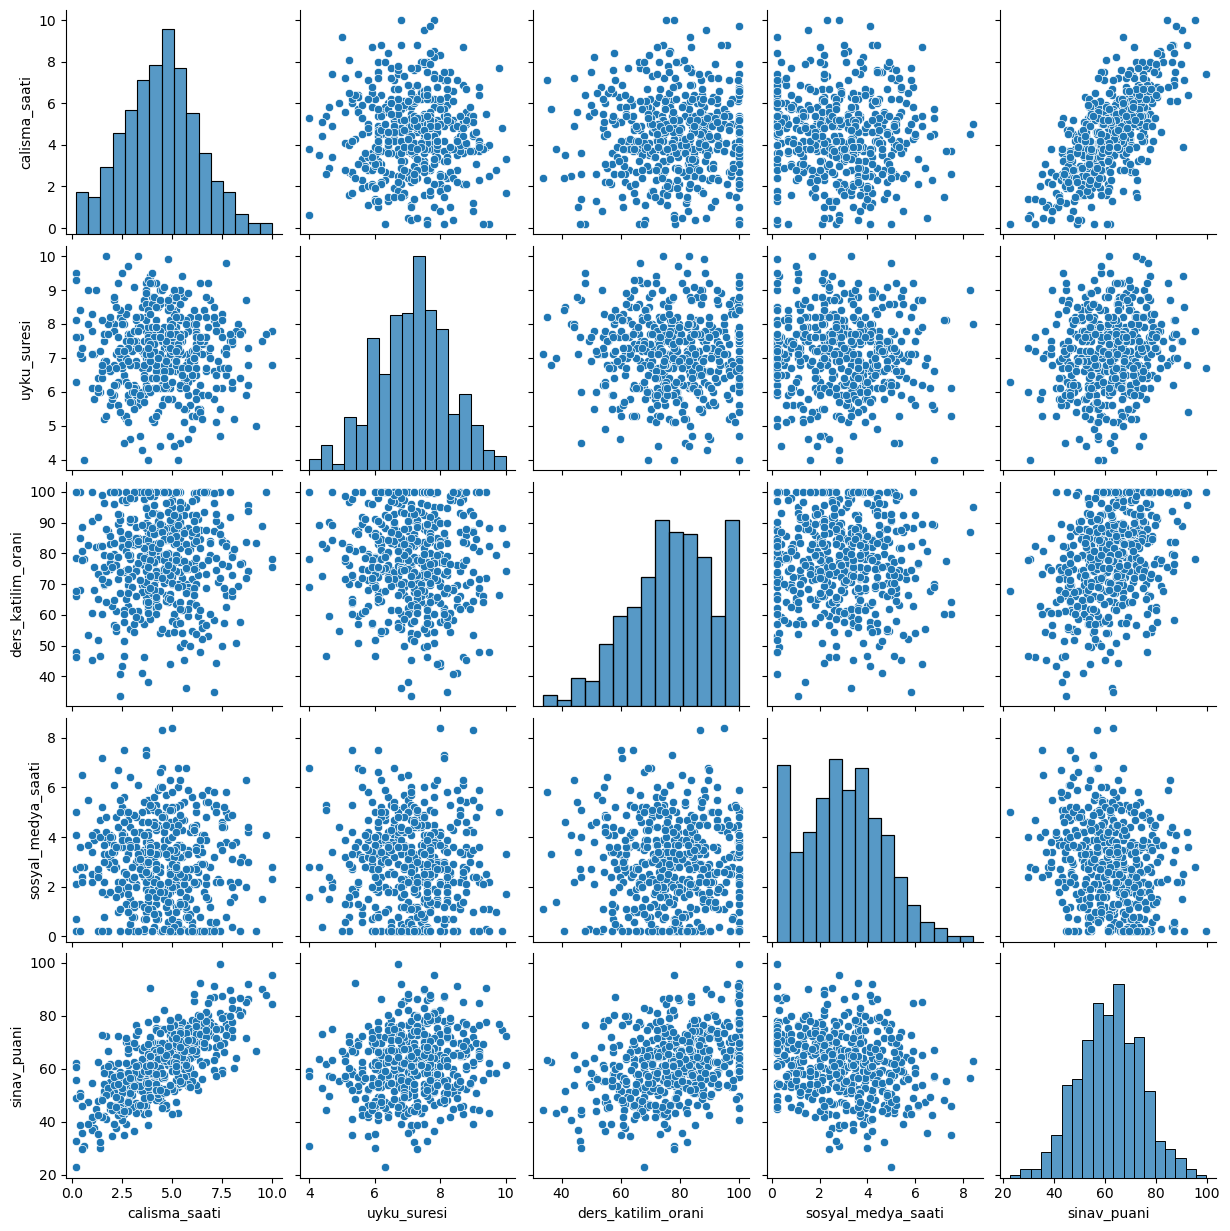

In [58]:
sns.pairplot(numeric_df)
plt.show()

+1 -> Güçlü pozitif doğrusal ilişki
-1 -> Güçlü negatif doğrusal ilişki
0 -> Doğrusal işilinin zayıf veya bulunamadığını gösterir.


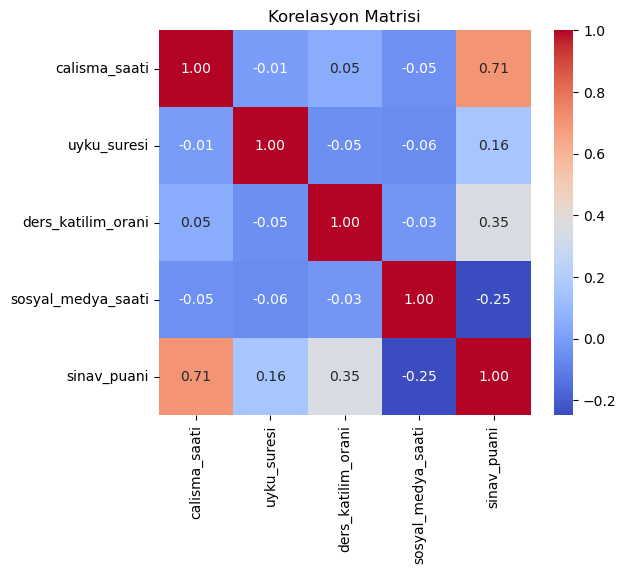

In [65]:
corr_matrix = numeric_df.corr()
plt.figure(figsize=(6,5))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Korelasyon Matrisi")
plt.show()

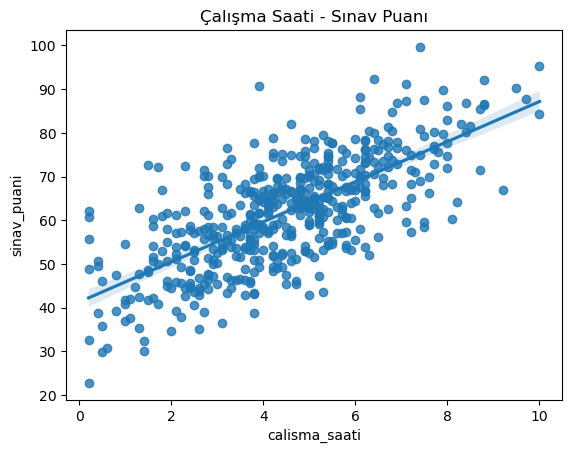

In [67]:
sns.regplot(
    x="calisma_saati",
    y="sinav_puani",
    data=df
)
plt.title("Çalışma Saati - Sınav Puanı")
plt.show()

X ve y
X:Bağımsız değişkenlerimiz -> Modelimize sunmuş oldugumuz girdiler -> Çalışma Saatimi,uyku süre,derse katılma,sosyal medya
y:Hedef değişken -> sınav puan -> Tahmin etmek istediğimiz değer
--------------
X -> 2D -> Birden fazla özellik
y -> 1D -> Tek bir hedef değişken
-----------------
X m2,oda sayısı,bina yaşı
y ev fiyatımız
------------------


In [70]:
#X = df[["calisma_saati","uyku_suresi","ders_katilim_orani","sosyal_medya_saati"]]
X=df.drop("sinav_puani",axis=1)
y=df["sinav_puani"]

In [71]:
print("X boyutu",X.shape)
print("y boyutu",y.shape)

X boyutu (500, 4)
y boyutu (500,)


In [72]:
from sklearn.model_selection import train_test_split


In [73]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

X_train : Eğitim girdilerimiz
y_train : Eğitim cevapları
X_test : Test girdilerimiz
y_test : Test cevaplarmız

In [75]:
print("X_train",X_train.shape)
print("X_test",X_test.shape)
print("y_tran",y_train.shape)
print("y_test",y_test.shape)

X_train (400, 4)
X_test (100, 4)
y_tran (400,)
y_test (100,)


In [76]:
#Scaling
# 0-10 / 0-100 / 0-12
#StandartScaler : Ortalamsını 0 standart sap. 1
#MinMaxScaler : Verilerimiz genellik 0 - 1 dönüştürüyor
scaler = StandardScaler()

In [77]:
#fit_tranform, transform
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
#data leakage
# cm,kg,TL

In [78]:
model = LinearRegression()

In [79]:
model.fit(X_train_scaled,y_train)


,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [80]:
model.intercept_

np.float64(61.72175)

In [83]:
model.coef_

array([ 8.50433348,  1.68746856,  3.8822954 , -2.6042838 ])

In [85]:
y_pred = model.predict(X_test_scaled)
print(y_pred[:10])

[69.49258989 58.31797131 66.17492561 82.43771648 48.82749876 60.77178734
 39.57217422 68.8148437  73.96799183 56.11283406]


In [86]:
new_student = pd.DataFrame({
    "calisma_saati":[5],
    "uyku_suresi":[7],
    "ders_katilim_orani":[90],
    "sosyal_medya_saati":[4]
})

new_student_scaled = scaler.transform(new_student)
predicted_score = model.predict(new_student_scaled)
print("Tahmini Sınav Notu:",predicted_score[0])

Tahmini Sınav Notu: 65.64062026604529


In [87]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 5.446228740098179
MSE: 51.46970019684446
RMSE: 7.174238649281501
R2 Score: 0.647259844805185


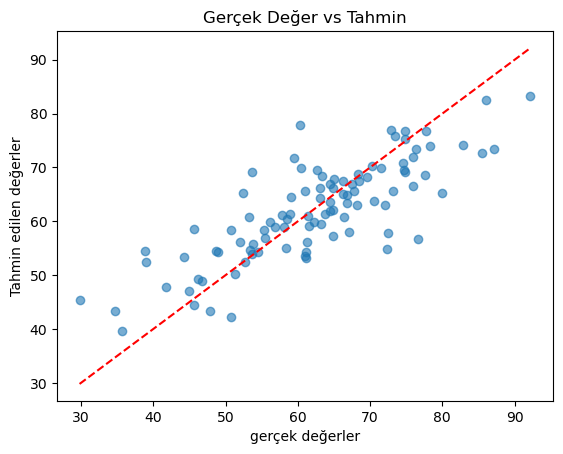

In [91]:
plt.scatter(
    y_test,
    y_pred,
    alpha=0.6
)

min_value = min(y_test.min(),y_pred.min())
max_value = max(y_test.max(),y_pred.max())

plt.plot(
    [min_value,max_value],
    [min_value,max_value],
    color="red",
    linestyle="--"
)
plt.xlabel("gerçek değerler")
plt.ylabel("Tahmin edilen değerler")
plt.title("Gerçek Değer vs Tahmin")
plt.show()